# SEC Third Down Conversion Stats

SEC Team Stats stats from `sql/Queries/sec_scoring_drive_conversions.sql` and `sql/Queries/sec_team_third_down.sql` .

In [1]:
import os
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine
import numpy as np
import matplotlib.pyplot as plt

# project root = the folder containing .env (works from notebooks/ or the root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".env").exists())
load_dotenv(ROOT / ".env")

engine = create_engine(
    f"postgresql+psycopg2://{os.environ['POSTGRES_USER']}:{os.environ['POSTGRES_PASSWORD']}"
    f"@localhost:5432/{os.environ['POSTGRES_DB']}"
)

In [25]:
query = (ROOT / "sql" / "Queries" / "sec_team_third_down.sql").read_text()

df = pd.read_sql(query, engine)
df

,team,games,third_down_plays,third_down_pass_plays,third_down_rush_plays,third_down_avg_distance,third_down_avg_yards_gained,third_down_conversion_rate,third_down_pass_conv,third_down_pass_conv_rate,...,drives_per_q3,drives_per_q4,avg_plays_per_drive,avg_plays_per_drive_1st_half,avg_plays_per_drive_2nd_half,avg_plays_per_drive_q1,avg_plays_per_drive_q2,avg_plays_per_drive_q3,avg_plays_per_drive_q4,avg_yards_per_drive
0,Georgia,4,41,24,17,5.49,10.20,0.537,11,0.458,...,3.8,2.8,4.52,4.62,4.42,5.23,4.00,5.07,3.55,37.0
1,LSU,4,61,36,25,6.16,6.66,0.525,18,0.500,...,3.8,2.3,6.30,6.27,6.33,5.00,8.00,5.87,7.11,40.2
2,Texas,4,60,37,23,6.58,5.88,0.500,15,0.405,...,3.5,2.0,6.52,6.23,6.82,5.40,6.92,5.79,8.63,34.5
3,Auburn,4,61,40,21,7.13,6.00,0.492,17,0.425,...,2.3,2.5,6.31,5.15,7.89,4.38,5.92,9.33,6.60,36.4
4,Mississippi State,4,47,26,21,7.06,7.00,0.489,9,0.346,...,3.3,2.5,6.06,5.83,6.30,5.55,6.08,6.23,6.40,45.6
5,Florida,4,45,22,23,7.80,8.89,0.489,10,0.455,...,3.3,2.3,6.22,6.78,5.64,7.00,6.58,5.23,6.22,47.3
6,Arkansas,4,63,41,22,7.37,6.25,0.460,16,0.390,...,2.8,2.3,6.54,5.96,7.30,6.25,5.71,6.64,8.11,31.7
7,Alabama,4,48,27,21,7.23,8.56,0.458,8,0.296,...,3.3,2.8,5.72,5.91,5.54,5.42,6.45,4.62,6.64,39.7
8,South Carolina,4,55,33,22,7.09,6.95,0.436,10,0.303,...,2.8,2.8,6.19,6.44,5.91,7.08,5.75,6.55,5.27,41.6
9,Ole Miss,4,46,32,14,7.22,4.78,0.435,11,0.344,...,3.0,2.5,6.00,6.09,5.91,6.08,6.09,5.92,5.90,39.1


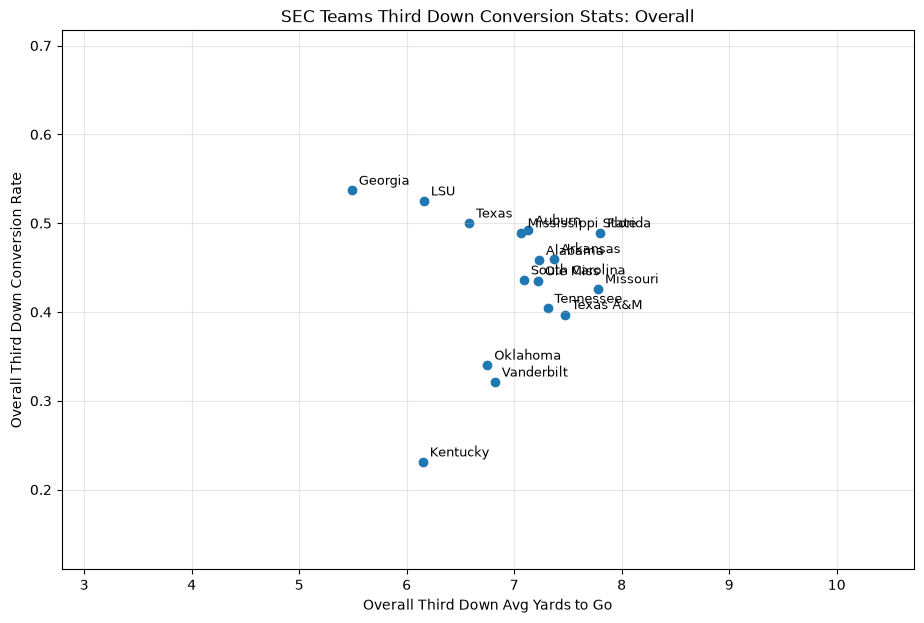

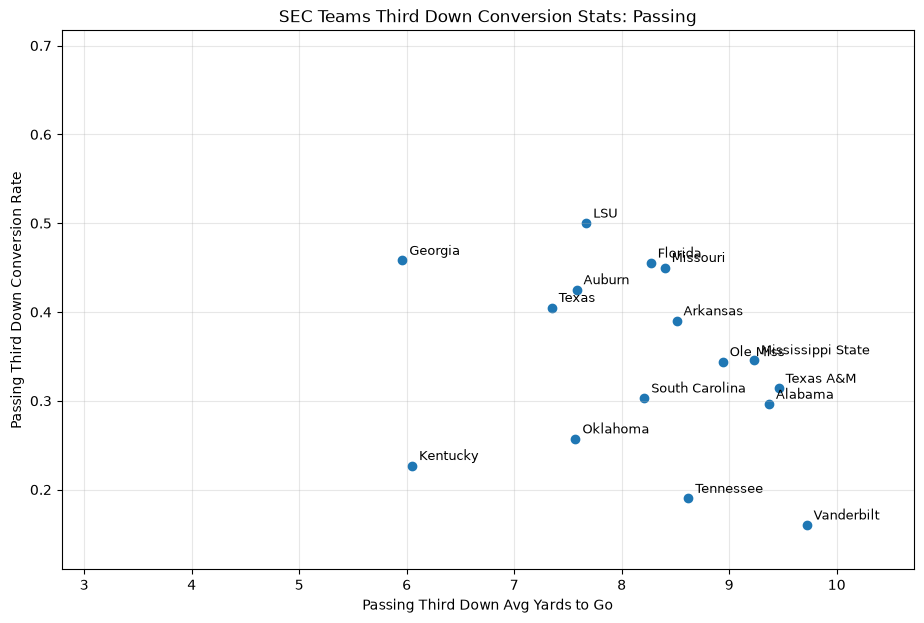

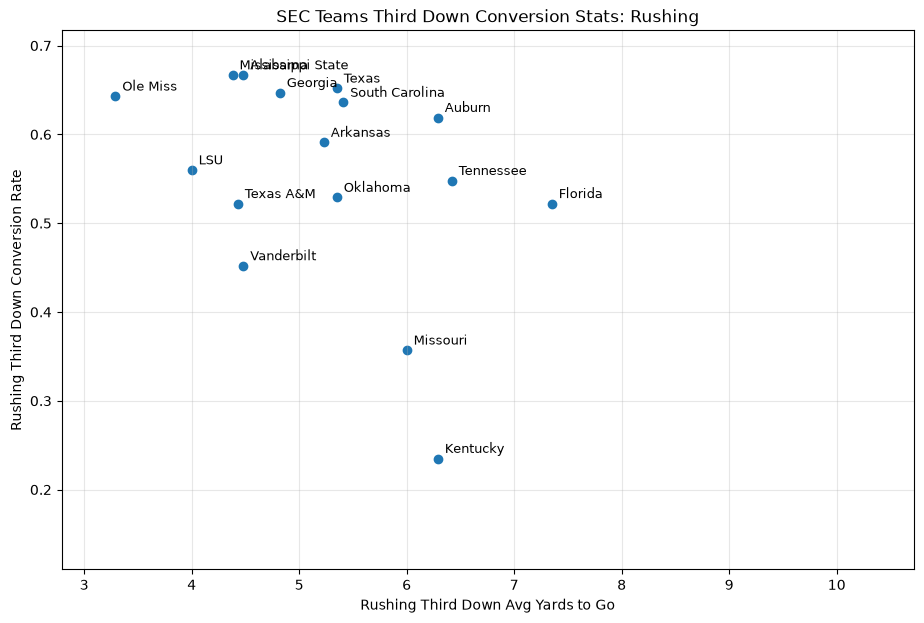

In [28]:
charts = [
    ('third_down_avg_distance',   'third_down_conversion_rate', 'Overall'),
    ('third_down_pass_avg_to_go', 'third_down_pass_conv_rate',  'Passing'),
    ('third_down_rush_avg_to_go', 'third_down_rush_conv_rate',  'Rushing'),
]

# same axis ranges on all three charts so the splits are directly comparable
x_cols = [x for x, _, _ in charts]
y_cols = [y for _, y, _ in charts]
x_min, x_max = df[x_cols].min().min() - 0.5, df[x_cols].max().max() + 1.0
y_min, y_max = df[y_cols].min().min() - 0.05, df[y_cols].max().max() + 0.05

for x_col, y_col, label in charts:
    fig, ax = plt.subplots(figsize=(11, 7))
    ax.scatter(df[x_col], df[y_col])

    for _, row in df.iterrows():
        ax.annotate(row['team'], (row[x_col], row[y_col]),
                    xytext=(5, 4), textcoords='offset points', fontsize=9)

    ax.set_xlabel(f'{label} Third Down Avg Yards to Go')
    ax.set_ylabel(f'{label} Third Down Conversion Rate')
    ax.set_title(f'SEC Teams Third Down Conversion Stats: {label}')
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.grid(alpha=0.3)
    plt.show()

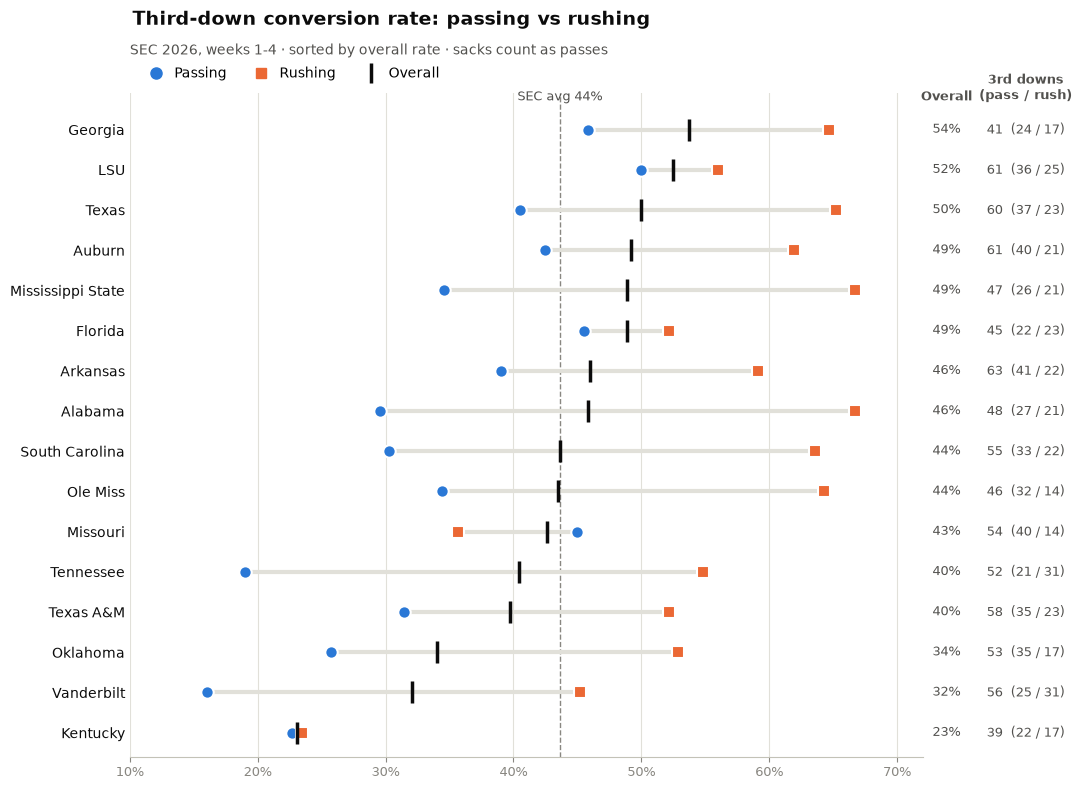

In [35]:
from matplotlib.ticker import PercentFormatter
from matplotlib.lines import Line2D

# colors: passing / rushing are a colorblind-safe pair; overall is plain ink
PASS, RUSH = '#2a78d6', '#eb6834'
INK, SECONDARY, MUTED, GRID = '#0b0b0b', '#52514e', '#898781', '#e1e0d9'

plot_df = df.sort_values('third_down_conversion_rate')   # best team ends up on top
y = np.arange(len(plot_df))
pass_rate = plot_df['third_down_pass_conv_rate']
rush_rate = plot_df['third_down_rush_conv_rate']
overall = plot_df['third_down_conversion_rate']
sec_avg = (df['third_down_conversion_rate'] * df['third_down_plays']).sum() / df['third_down_plays'].sum()

fig, ax = plt.subplots(figsize=(11, 8))

# line between each team's passing and rushing rate = the gap between them
ax.hlines(y, np.minimum(pass_rate, rush_rate), np.maximum(pass_rate, rush_rate),
          color=GRID, linewidth=3, zorder=1)
ax.scatter(pass_rate, y, s=80, marker='o', color=PASS, edgecolor='white', linewidth=1.5, zorder=3)
ax.scatter(rush_rate, y, s=70, marker='s', color=RUSH, edgecolor='white', linewidth=1.5, zorder=3)
ax.scatter(overall, y, s=260, marker='|', color=INK, linewidths=2.5, zorder=4)

# SEC average reference line
ax.axvline(sec_avg, color=MUTED, linestyle='--', linewidth=1, zorder=0)
ax.text(sec_avg, len(plot_df) - 0.35, f'SEC avg {sec_avg:.0%}', color=SECONDARY,
        fontsize=9, ha='center', va='bottom')

# right-hand columns: overall rate, and total 3rd down plays (pass / rush)
col_overall, col_plays = 1.03, 1.13
header_y = len(plot_df) - 0.35
ax.text(col_overall, header_y, 'Overall', transform=ax.get_yaxis_transform(),
        fontsize=9, color=SECONDARY, fontweight='bold', va='bottom', ha='center')
ax.text(col_plays, header_y, '3rd downs\n(pass / rush)', transform=ax.get_yaxis_transform(),
        fontsize=9, color=SECONDARY, fontweight='bold', va='bottom', ha='center')
for yi, (_, row) in zip(y, plot_df.iterrows()):
    ax.text(col_overall, yi, f"{row['third_down_conversion_rate']:.0%}",
            transform=ax.get_yaxis_transform(), fontsize=9, color=SECONDARY,
            va='center', ha='center')
    ax.text(col_plays, yi,
            f"{row['third_down_plays']}  ({row['third_down_pass_plays']} / {row['third_down_rush_plays']})",
            transform=ax.get_yaxis_transform(), fontsize=9, color=SECONDARY,
            va='center', ha='center')

# axes: team names on the left, light vertical gridlines, no box
ax.set_yticks(y)
ax.set_yticklabels(plot_df['team'], fontsize=10, color=INK)
ax.set_ylim(-0.6, len(plot_df) - 0.1)
ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax.set_xlim(0.10, 0.72)
ax.tick_params(axis='x', colors=MUTED, labelsize=9)
ax.tick_params(axis='y', length=0)
ax.grid(axis='x', color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ['top', 'right', 'left']:
    ax.spines[side].set_visible(False)
ax.spines['bottom'].set_color('#c3c2b7')

# title, subtitle, legend
fig.suptitle('Third-down conversion rate: passing vs rushing', x=0.125, ha='left',
             fontsize=14, fontweight='bold', color=INK)
ax.set_title('SEC 2026, weeks 1-4 · sorted by overall rate · sacks count as passes',
             loc='left', fontsize=10, color=SECONDARY, pad=28)
ax.legend(handles=[
    Line2D([], [], marker='o', linestyle='', markersize=8, color=PASS, label='Passing'),
    Line2D([], [], marker='s', linestyle='', markersize=7, color=RUSH, label='Rushing'),
    Line2D([], [], marker='|', linestyle='', markersize=14, markeredgewidth=2.5, color=INK, label='Overall'),
], loc='lower left', bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=10,
   handletextpad=0.3, columnspacing=1.5)

plt.tight_layout()
plt.show()

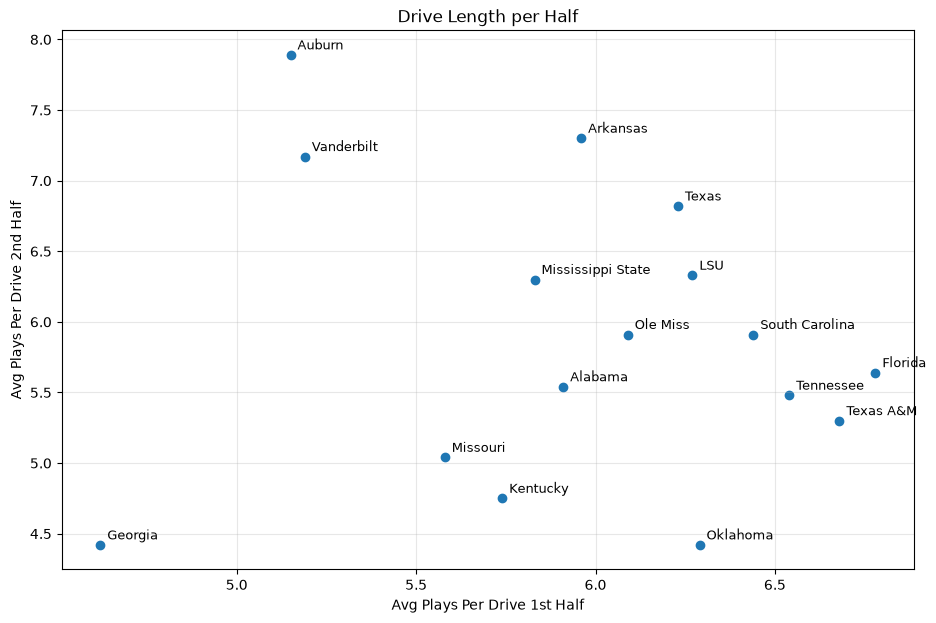

In [ ]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(df['avg_plays_per_drive_1st_half'], df['avg_plays_per_drive_2nd_half'])

for _, row in df.iterrows():
    ax.annotate(row['team'], (row['avg_plays_per_drive_1st_half'], row['avg_plays_per_drive_2nd_half']),
                xytext=(5, 4), textcoords='offset points', fontsize=9)

ax.set_xlabel('Avg Plays Per Drive 1st Half')
ax.set_ylabel('Avg Plays Per Drive 2nd Half')
ax.set_title('Dr')
ax.grid(alpha=0.3)
plt.show()

In [24]:
query = (ROOT / "sql" / "Queries" / "sec_scoring_drive_conversions.sql").read_text()

scoring_drives = pd.read_sql(query, engine)
scoring_drives

,team,drives,scoring_drives,td_drives,fg_drives,scoring_drive_rate,sd_third_att,sd_third_conv,sd_third_conv_rate,sd_fourth_att,...,nsd_fourth_conv,nsd_conversions_per_drive,nsd_pass_att,nsd_pass_conv,nsd_pass_conv_rate,nsd_pass_avg_to_go,nsd_rush_att,nsd_rush_conv,nsd_rush_conv_rate,nsd_rush_avg_to_go
0,Arkansas,46,17,10,7,0.370,30.0,19.0,0.633,4.0,...,0.0,0.34,25.0,4.0,0.160,9.04,12.0,6.0,0.500,5.92
1,Texas,44,22,15,7,0.500,36.0,24.0,0.667,4.0,...,0.0,0.27,16.0,2.0,0.125,8.56,11.0,4.0,0.364,7.45
2,Vanderbilt,44,16,11,5,0.364,24.0,10.0,0.417,9.0,...,1.0,0.32,19.0,0.0,0.000,8.16,18.0,9.0,0.500,4.50
3,Auburn,45,17,13,4,0.378,24.0,16.0,0.667,4.0,...,1.0,0.54,24.0,6.0,0.250,8.58,17.0,9.0,0.529,5.82
4,South Carolina,47,23,17,6,0.489,31.0,17.0,0.548,7.0,...,1.0,0.33,16.0,1.0,0.063,8.94,12.0,7.0,0.583,6.17
5,Texas A&M,49,19,13,6,0.388,26.0,15.0,0.577,4.0,...,3.0,0.37,21.0,1.0,0.048,11.57,18.0,9.0,0.500,5.00
6,LSU,50,24,19,5,0.480,28.0,22.0,0.786,2.0,...,3.0,0.50,23.0,6.0,0.261,7.74,15.0,7.0,0.467,5.13
7,Oklahoma,47,14,10,4,0.298,17.0,12.0,0.706,1.0,...,0.0,0.18,27.0,2.0,0.074,7.48,11.0,4.0,0.364,6.45
8,Alabama,47,29,21,8,0.617,33.0,19.0,0.576,4.0,...,0.0,0.17,9.0,0.0,0.000,9.67,6.0,3.0,0.500,6.33
9,Mississippi State,47,29,23,6,0.617,29.0,20.0,0.690,3.0,...,1.0,0.22,13.0,1.0,0.077,10.15,7.0,3.0,0.429,5.57


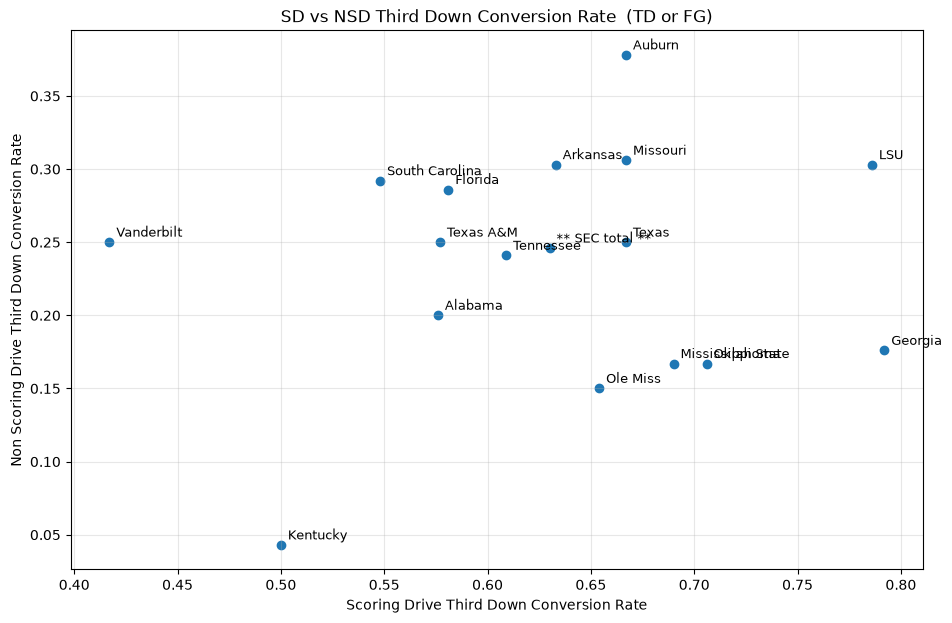

In [20]:
fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(scoring_drives['sd_third_conv_rate'], scoring_drives['nsd_third_conv_rate'])

for _, row in scoring_drives.iterrows():
    ax.annotate(row['team'], (row['sd_third_conv_rate'], row['nsd_third_conv_rate']),
                xytext=(5, 4), textcoords='offset points', fontsize=9)

ax.set_xlabel('Scoring Drive Third Down Conversion Rate')
ax.set_ylabel('Non Scoring Drive Third Down Conversion Rate')
ax.set_title('SD vs NSD Third Down Conversion Rate  (TD or FG)')
ax.grid(alpha=0.3)
plt.show()